# Iris Classification: Logistic Regression vs K-Nearest Neighbors

**Goal:** preprocess the Iris dataset, train Logistic Regression and KNN classifiers, evaluate them (Accuracy, Precision, Recall, F1-Score, Confusion Matrix) and compare the results.

**Steps**
1. Load and explore the data
2. Preprocessing (cleaning, label encoding, train/test split, scaling)
3. Logistic Regression
4. K-Nearest Neighbors (including choosing *k*)
5. Evaluation and confusion matrices
6. Comparison and analysis

## 1. Import libraries and load data

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42

In [21]:
df = pd.read_csv("Iris.csv")   # keep Iris.csv in the same folder as this notebook
print("Shape:", df.shape)
df.head()

Shape: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


## 2. Exploratory data analysis

In [22]:
df.info()
print()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB



,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [23]:
print("Missing values per column:\n", df.isnull().sum(), sep="")
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass distribution:\n", df["Species"].value_counts(), sep="")

Missing values per column:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Duplicate rows: 0

Class distribution:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


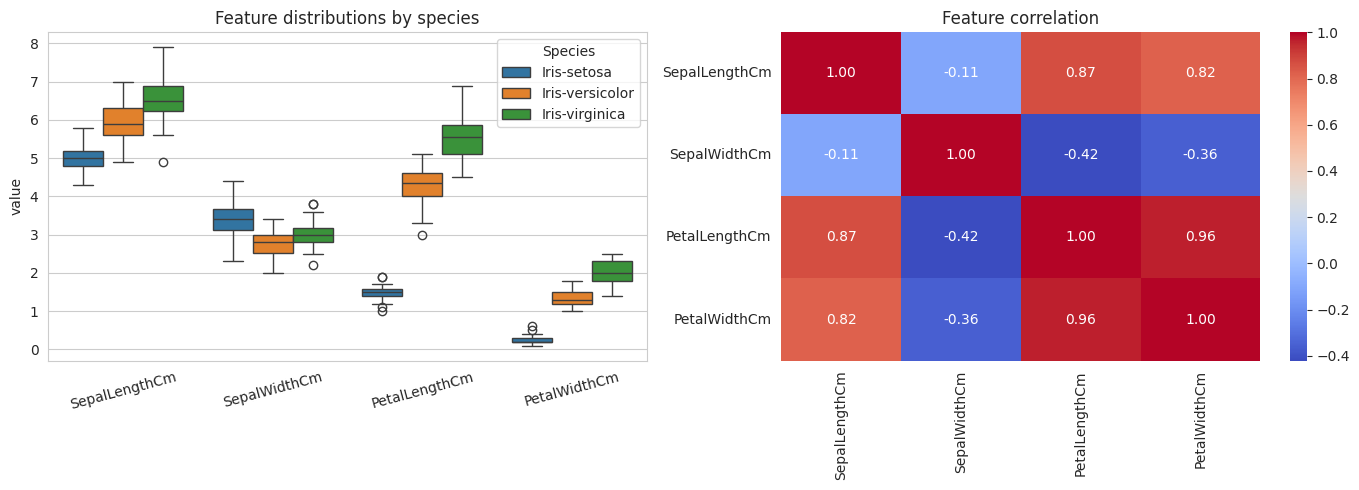

In [24]:
features = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df.melt(id_vars="Species", value_vars=features), x="variable", y="value",
            hue="Species", ax=axes[0])
axes[0].set_title("Feature distributions by species")
axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=15)

sns.heatmap(df[features].corr(), annot=True, cmap="coolwarm", fmt=".2f", ax=axes[1])
axes[1].set_title("Feature correlation")
plt.tight_layout(); plt.show()

## 3. Data preprocessing

- **Drop `Id`**: it is only a row index and carries no information about the species.
- **Missing values / duplicates**: none were found above, so no imputation or removal is needed.
- **Encode the target**: convert species names to integers.
- **Stratified train/test split (80/20)**: keeps the 1/3-1/3-1/3 class balance in both sets.
- **Feature scaling (StandardScaler)**: fitted on the training set *only*, then applied to the test set, to avoid data leakage. Scaling matters most for KNN because it is distance-based, and it also helps Logistic Regression converge.

In [25]:
df_clean = df.drop(columns="Id").drop_duplicates().reset_index(drop=True)

X = df_clean[features]
le = LabelEncoder()
y = le.fit_transform(df_clean["Species"])
class_names = [c.replace("Iris-", "") for c in le.classes_]
print("Encoding:", dict(zip(class_names, range(len(class_names)))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit on train only
X_test_s = scaler.transform(X_test)

print(f"Train: {X_train_s.shape}, Test: {X_test_s.shape}")
print("Train class counts:", np.bincount(y_train), "| Test class counts:", np.bincount(y_test))

Encoding: {'setosa': 0, 'versicolor': 1, 'virginica': 2}
Train: (117, 4), Test: (30, 4)
Train class counts: [38 40 39] | Test class counts: [10 10 10]


## 4. Logistic Regression

In [26]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_s, y_train)
y_pred_lr = log_reg.predict(X_test_s)
print("Logistic Regression test accuracy:", round(accuracy_score(y_test, y_pred_lr), 4))

Logistic Regression test accuracy: 0.9333


## 5. K-Nearest Neighbors

We are considering k=3

In [27]:
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_s, y_train)
y_pred_knn = knn.predict(X_test_s)
print(f"KNN (k={3}) test accuracy:", round(accuracy_score(y_test, y_pred_knn), 4))

KNN (k=3) test accuracy: 0.9333


## 6. Evaluation

Precision, Recall and F1 are computed per class and also as **macro averages** (unweighted mean over the three species).

In [28]:
for name, pred in [("Logistic Regression", y_pred_lr), (f"KNN (k={best_k})", y_pred_knn)]:
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, pred, target_names=class_names, digits=3))

Logistic Regression
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

KNN (k=3)
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.833     1.000     0.909        10
   virginica      1.000     0.800     0.889        10

    accuracy                          0.933        30
   macro avg      0.944     0.933     0.933        30
weighted avg      0.944     0.933     0.933        30



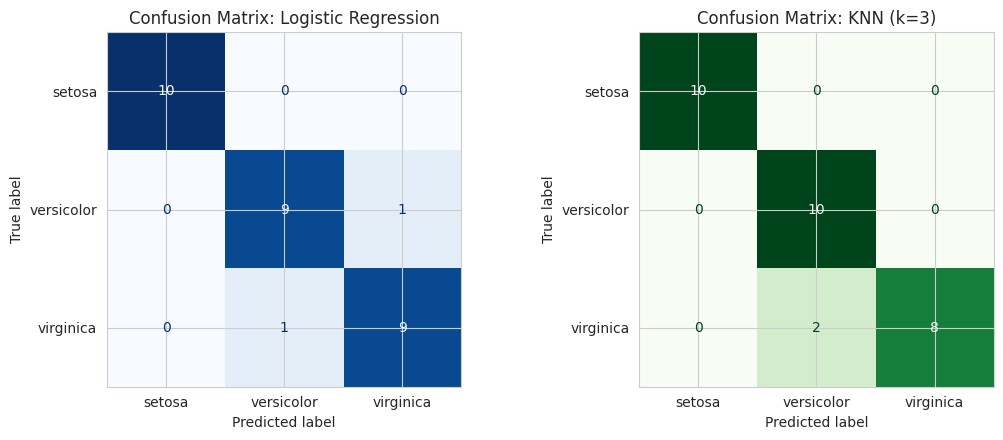

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, pred, cmap) in zip(axes, [("Logistic Regression", y_pred_lr, "Blues"),
                                         (f"KNN (k={best_k})", y_pred_knn, "Greens")]):
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap=cmap, colorbar=False)
    ax.set_title(f"Confusion Matrix: {name}")
plt.tight_layout(); plt.show()

## 7. Model comparison

In [30]:
def summarize(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (macro)": precision_score(y_true, y_pred, average="macro"),
        "Recall (macro)": recall_score(y_true, y_pred, average="macro"),
        "F1-Score (macro)": f1_score(y_true, y_pred, average="macro"),
    }

results = pd.DataFrame([summarize("Logistic Regression", y_test, y_pred_lr),
                        summarize(f"KNN (k={best_k})", y_test, y_pred_knn)]).set_index("Model")
results.round(4)

,Accuracy,Precision (macro),Recall (macro),F1-Score (macro)
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
KNN (k=3),0.9333,0.9444,0.9333,0.9327
